In [1]:
from pathlib import Path

import torch

# from rtnls_models.inference.segmentation import (
#     SegmentationEnsemble,
# )
# from rtnls_models.run import preprocess_for_inference
# from rtnls_models.utils.config import load_config
from rtnls_enface.loader import FundusLoader
from rtnls_enface.qc.validators import GeneralQCValidator

In [2]:
ds_path = Path("/mnt/ssd1/fundus_prep/fundus_prep")

# input folders. these are the folders where we stored the preprocessed images
rgb_path = ds_path / "rgb"
ce_path = ds_path / "ce"

# these are the output folders for:
av_path = ds_path / "av"  # artery-vein segmentations
discs_path = ds_path / "discs"  # optic disc segmentations
vessels_path = ds_path / "vessels"  # optic disc segmentations

device = torch.device("cuda:0")  # device to use for inference


## Preprocess

In [3]:
# files = list((ds_path / "original").glob("*"))
# bounds = preprocess_for_inference(
#     files,  # List of image files
#     rgb_path=ds_path / "rgb",  # Output path for RGB images
#     ce_path=ds_path / "ce",  # Output path for Contrast Enhanced images
#     n_jobs=4,  # number of preprocessing workers
# )
# df_bounds = pd.DataFrame(bounds).set_index("id")
# df_bounds.to_csv(ds_path / "meta.csv")

## Disc segmentation

In [4]:
# device = torch.device("cuda:0")
# disc_ensemble = SegmentationEnsemble(load_config("disc"), device=device)
# disc_ensemble.predict_preprocessed(
#     rgb_path, ce_path, dest_path=discs_path, num_workers=2
# )

## Vessel segmentation

In [5]:
# av_ensemble = SegmentationEnsemble(load_config("vessels"), device=device)
# # run the model, pass the path for the outputs
# av_ensemble.predict_preprocessed(
#     rgb_path, ce_path, dest_path=vessels_path, num_workers=2
# )

In [6]:
loader = FundusLoader.from_folders(discs_path, rgb_path, meta_path=ds_path / "meta.csv")

Folder disc_path: 298422 files
Folder fundus_path: 298422 files


In [13]:
validator = GeneralQCValidator()

In [40]:
ret = loader.make_object("519744")

In [41]:
validator(ret)

False

<Axes: >

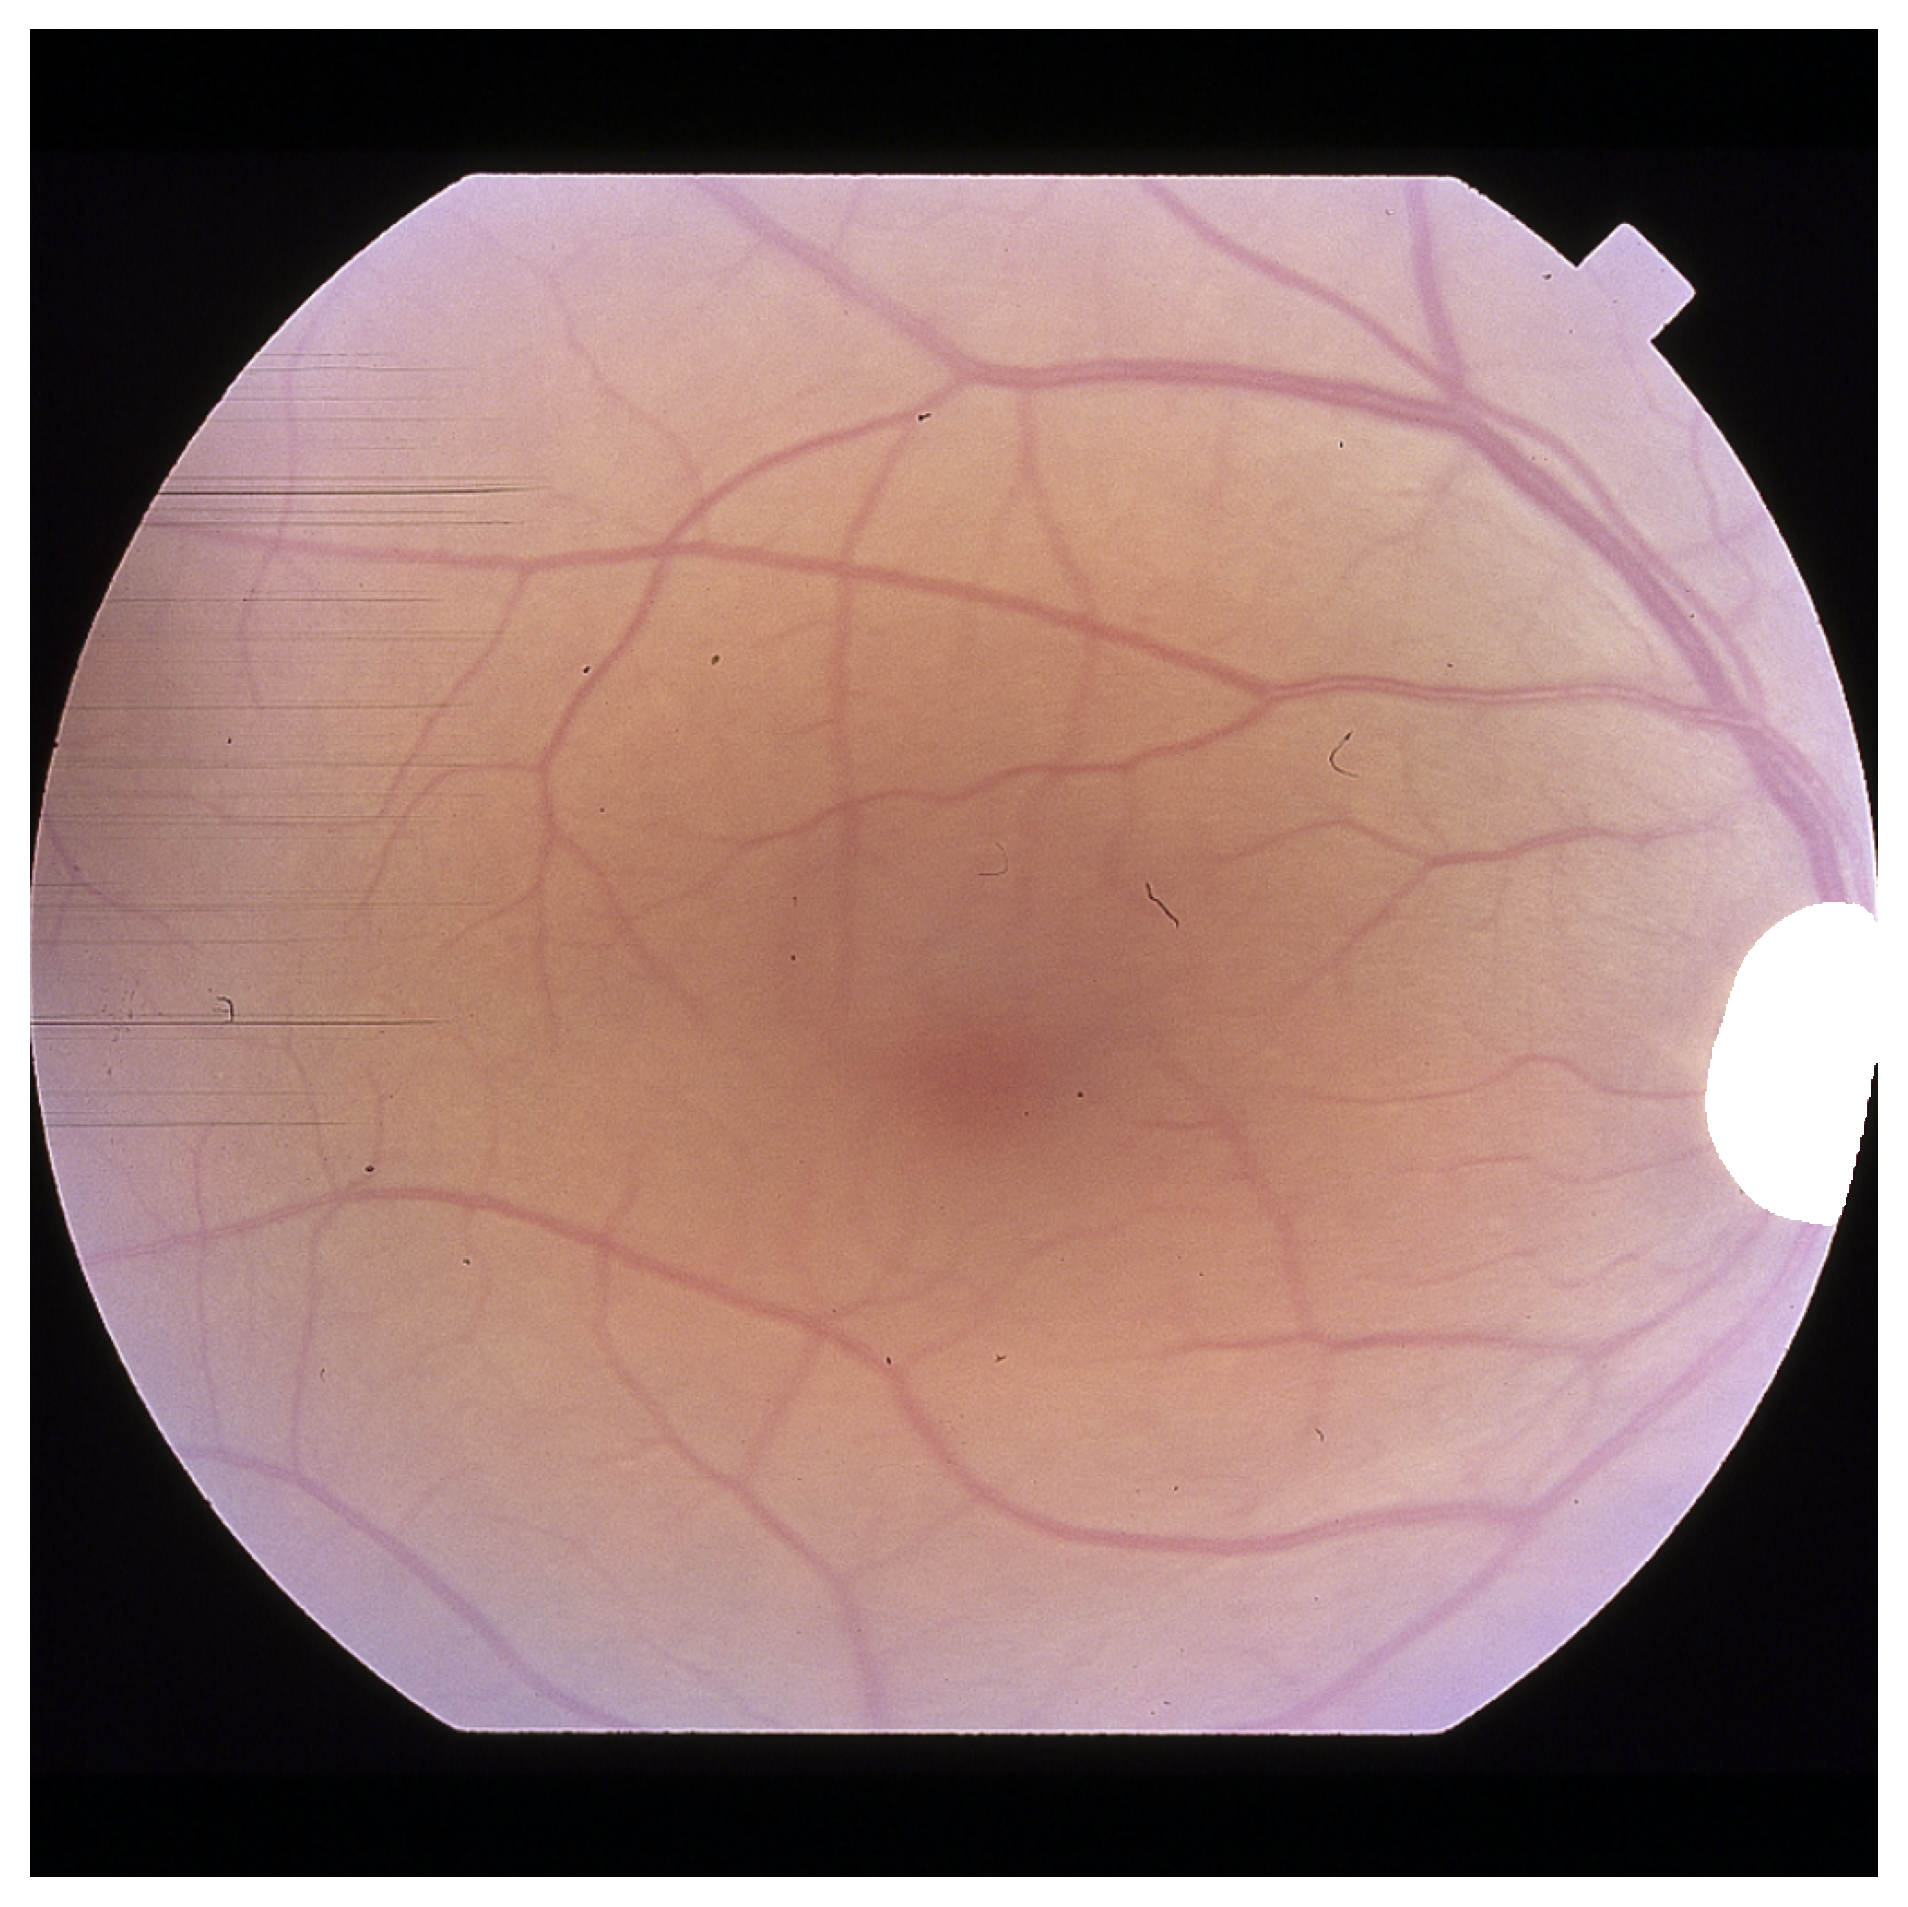

In [42]:
ret.plot()